In [1]:
import os
# 把 Graphviz 的路径加入 PATH
os.environ["PATH"] += os.pathsep + "/usr/local/bin"

# 测试
!which dot

/usr/local/bin/dot


In [2]:
import math
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0
        self._backward = lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data+other.data, (self, other), '+')
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
        
    def __radd__(self, other): # other + self
        return self + other


    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __truediv__(self, other):
        return self*(other**-1)

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only support int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')
        def _backward():
            self.grad += other*(self.data**(other-1)) * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other):
        return self * other

    def tanh(self):
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad += (1-t**2)* out.grad

        out._backward = _backward
        
        return out

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')
        def _backward():
            self.grad += out.grad * out.data
        out._backward = _backward
        return out

    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad =1.0
        for node in reversed(topo):
            node._backward()
    

In [3]:
a = Value(2)
b=Value(4)
print(-a)

Value(data=-2)


In [4]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this op node to the value node
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [5]:
def lol():
    h=0.0001
    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e+c; d.label ='d'
    f = Value(-2.0); f.label ='f'
    L =d*f; L.label ='L'
    L1 = L.data

    a = Value(2+h, label='a')
    b = Value(-3, label='b')
    c = Value(10, label='c')
    e = a*b; e.label='e'
    d = e+c; d.label ='d'
    f = Value(-2.0); f.label ='f'
    L =d*f; L.label ='L'
    L2 = L.data

    print((L2-L1)/h)
lol()

6.000000000021544


In [6]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1=Value(-3, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.88173, label='b')
x1w1 = x1*w1; x1w1.label='x1w1'
x2w2= x2*w2; x2w2.label='x2w2'
x1w1x2w2 = x1w1+ x2w2; x1w1x2w2.label='x1w1+x2w2'
n=x1w1x2w2+b; n.label='n'
o = n.tanh();o.label='o'
o.backward()


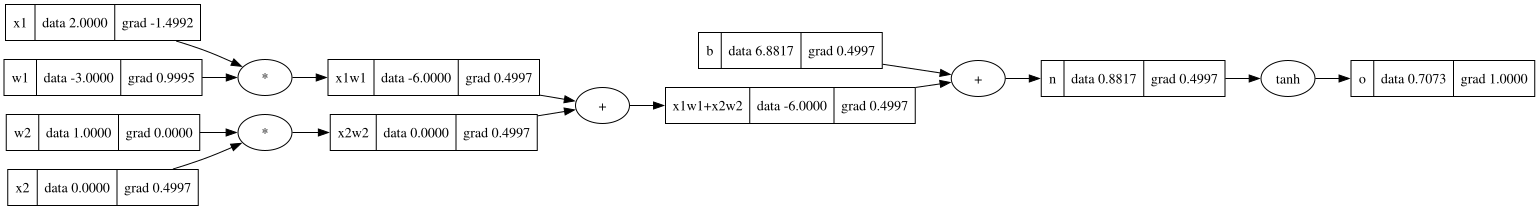

In [7]:
draw_dot(o)

In [8]:
o.backward()

In [9]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1=Value(-3, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.88173, label='b')
x1w1 = x1*w1; x1w1.label='x1w1'
x2w2= x2*w2; x2w2.label='x2w2'
x1w1x2w2 = x1w1+ x2w2; x1w1x2w2.label='x1w1+x2w2'
n=x1w1x2w2+b; n.label='n'
e = (2*n).exp()
o = (e-1)/(e+1);o.label='o'
o.backward()


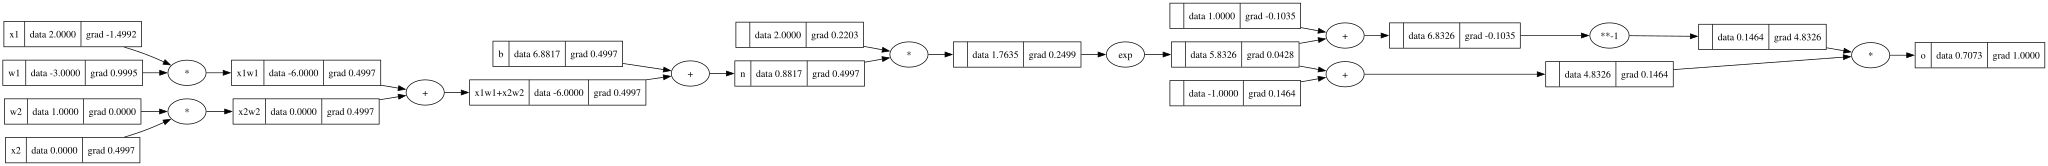

In [10]:
draw_dot(o)

In [127]:
import random
class Neuron:
    def __init__(self, nin): # 每个神经元接收nin个输入
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b) 
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout): # 每层有nout个神经元，每个神经元接收nin个输入 
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x): # 对于输入x, 依次调用每个神经元，将输出组成一个向量
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs)==1 else outs

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

class MLP:
    def __init__(self, nin, nouts): # nin:输入层的纬度，nouts:每层神经元的数量
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return  [p for layer in self.layers for p in layer.parameters()]



In [128]:
x = [2.0, 3.0, -1]
n = MLP(3,[4, 4, 1])
n(x)

Value(data=0.8285888505733481)

In [129]:
n.parameters()

[Value(data=0.15837738943532598),
 Value(data=0.46203450238050636),
 Value(data=0.17918169684996732),
 Value(data=0.8298552307132081),
 Value(data=0.2923920272964535),
 Value(data=0.35710156755909583),
 Value(data=0.8089431517802685),
 Value(data=-0.17871237536323337),
 Value(data=0.45243351531608944),
 Value(data=0.5963554944095488),
 Value(data=-0.4805515430356464),
 Value(data=0.34051422254016295),
 Value(data=0.7906008188996694),
 Value(data=0.9914263425501524),
 Value(data=0.8275534816638523),
 Value(data=0.657956729549148),
 Value(data=0.6809649261000801),
 Value(data=-0.4902236392944872),
 Value(data=0.0805836698482445),
 Value(data=-0.6712169450563434),
 Value(data=0.4028371158724058),
 Value(data=0.48349180345536213),
 Value(data=-0.6021753538430208),
 Value(data=0.10968033151094758),
 Value(data=0.31458258709799347),
 Value(data=0.70566725555373),
 Value(data=-0.9905664238893328),
 Value(data=0.04192047715527014),
 Value(data=-0.5340666019211038),
 Value(data=0.55853128847415

In [130]:
xs = [[2,3,-1],
     [3,-1,0.5],
     [0.5,1,1],
     [1,1,-1]]
ys = [1,-1,-1,1]


In [131]:
for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum((yout-ygt)**2 for ygt,yout in zip(ys, ypred))

    # backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -0.05 * p.grad
    print(k, loss.data)

0 6.69197703038988
1 5.886565483097786
2 4.622444074001131
3 3.9696787139490084
4 3.7667709093225663
5 3.523387525252026
6 3.156925711588591
7 2.588598883532863
8 1.909862271682305
9 1.34131269181374
10 0.9515359420488393
11 0.7019771325590363
12 0.5405703523040909
13 0.4321263700105199
14 0.35607407461347
15 0.30061247809216896
16 0.25879170124373446
17 0.2263548761855004
18 0.20059142201344965
19 0.17971246891624768


In [122]:
ypred

[Value(data=1.0), Value(data=-1.0), Value(data=-1.0), Value(data=1.0)]

In [115]:
ypred = [n(x) for x in xs]
loss = sum((yout-ygt)**2 for ygt,yout in zip(ys, ypred)) 
loss

Value(data=0.007562356413105352)

In [116]:
loss.backward()

In [117]:
for p in n.parameters():
    p.data += -0.1 * p.grad

In [118]:
ypred

[Value(data=0.9180640235338754),
 Value(data=-0.9999386039280757),
 Value(data=-0.9999715592331347),
 Value(data=0.9708650108067094)]